# BC Environmental Monitoring Data QA/QC & Analysis

**Site:** Erickson Creek at mouth — EMS location `0200097` (*EVCC - ELKVIEW (PE425) ERICKSON CREEK AT MOUTH*, River, Stream, or Creek)
**Primary parameter:** Nitrate (NO3) Dissolved — EMS code `1110`, mg/L
**Supporting parameter:** Field water temperature — EMS code `TEMF`, °C
**Period:** 6 January 2025 – 29 June 2026
**Source:** Government of British Columbia, Environmental Monitoring Data System (EnMoDS) public export `this_yr.csv`

## 1. Objective

Work through a practical environmental-monitoring data workflow on real public data:

1. take one site/parameter record out of a large provincial export,
2. review its quality with transparent, documented QA/QC rules,
3. keep every record traceable to the raw file and **flag** questionable records for review instead of deleting them,
4. summarise and visualise the record, and
5. state only what the data support.

This is an exploratory data-quality and temporal analysis. It is **not** a regulatory compliance assessment, and no water-quality guideline comparison is made.

## 2. Data Source

- **Provider:** Government of British Columbia — Environmental Monitoring Data System (EnMoDS), public data export (`this_yr.csv`, current-year results). See `data/README.md` for how to obtain it.
- **Raw file:** `data/raw/this_yr.csv` — 1,883,073,291 bytes (about 1.9 GB), 3,092,148 result rows, 67 columns, sample dates 31 Dec 2024 – 19 Sep 2026. The raw file is **not** in the repository and was never modified.
- **Earlier steps (scripts, run against the raw file):**
  - `scripts/01_profile_raw_dataset.py` — DuckDB profiling of the whole file without loading it into pandas (outputs in `outputs/profiling/`).
  - `scripts/02_extract_selected_subset.py` — DuckDB extraction of the selected site/parameters to `data/selected_monitoring_data.csv`, keeping all 67 original columns and adding `source_row_number` (the record's 1-based data-row position in the raw file).
- **This notebook** starts from the 567-record extracted file, so it runs in seconds and does not need the raw file.

Each EnMoDS row is one result for one parameter from one sample. Note the naming: `Observed_Property_ID` holds the readable parameter name and `Observed_Property_Name` holds the EMS parameter code.

## 3. Libraries
Only pandas, NumPy (installed with pandas) and Matplotlib are used in the analysis.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

DATA_FILE = Path("data/selected_monitoring_data.csv")
OUT_DIR = Path("outputs")
FIG_DIR = Path("figures")
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Consistent figure styling (colour-blind-safe blue/orange pair, recessive grid)
NITRATE_COLOR, TEMP_COLOR, REVIEW_COLOR = "#2a78d6", "#eb6834", "#eb6834"
PASS_COLOR, EXCLUDED_COLOR, INK, MUTED = "#2a78d6", "#b5b3ad", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.edgecolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

## 4. Load Extracted Dataset
Everything is read as text (`dtype=str`) so the original values — including `Result_Value` — stay exactly as they appear in the raw export. Numeric and date versions are created later as **new** columns.

In [2]:
raw = pd.read_csv(DATA_FILE, dtype=str)
print(f"{len(raw)} records x {raw.shape[1]} columns "
      f"(67 original EnMoDS columns + source_row_number)")
raw.groupby(["Observed_Property_Name", "Observed_Property_ID", "Collection_Method", "Medium"]) \
   .size().rename("records").to_frame()

567 records x 68 columns (67 original EnMoDS columns + source_row_number)


records
Observed_Property_Name Observed_Property_ID                Collection_Method                  Medium                
1110                   Nitrate (NO3) Dissolved (fl. conc.) Grab                               Water - Fresh      138
TEMF                   Temperature-Field (temp.)           Grab                               Water - Fresh      159
                                                           Time Composite: Continuous Monitor Water - Other      270

## 5. Initial Data Inspection
A compact look at the fields that matter for QA/QC: units, classification, QC sample type, result status, detection information, method, and missing values in key fields.

In [3]:
key_fields = ["Result_Unit", "Data_Classification", "QC_Type", "Result_Status", "Result_Grade",
              "Detection_Condition", "Method_Detection_Limit", "Analysis_Method", "Analyzing_Agency",
              "Sampling_Agency"]

def value_summary(series):
    counts = series.fillna("(blank)").value_counts()
    return "; ".join(f"{v} ({n})" for v, n in counts.items())

inspection = (raw.groupby(["Observed_Property_Name", "Collection_Method"])[key_fields]
                 .agg(value_summary).T)
inspection

Observed_Property_Name                                                         1110                                                         TEMF                                   
Collection_Method                                                              Grab                                                         Grab Time Composite: Continuous Monitor
Result_Unit                                                              mg/L (138)                                                   degC (159)                         degC (270)
Data_Classification                                                       LAB (138)                                           FIELD_RESULT (159)                 FIELD_RESULT (270)
QC_Type                                                                NORMAL (138)                                                 NORMAL (159)                       NORMAL (270)
Result_Status                                                     Preliminary (138)                                            Preliminary (159)                  Preliminary (270)
Result_Grade                                                         Ungraded (138)                                               Ungraded (159)                     Ungraded (270)
Detection_Condition                                                   (blank) (138)                                                (blank) (159)                      (blank) (270)
Method_Detection_Limit                                       0.005 (99); 0.025 (39)                                                (blank) (159)                      (blank) (270)
Analysis_Method                                            Ion Chromatography (138)                                                (blank) (159)                      (blank) (270)
Analyzing_Agency                                                          ALS (138)                                                (blank) (159)                      (blank) (270)
Sampling_Agency         105 - Elkview Coal Corp. Central Lab (99); EVR Operation...  105 - Elkview Coal Corp. Central Lab (115); EVR Operatio...          EVR Operations Ltd. (270)

In [4]:
missing_key = raw[["Location_ID", "Observed_Date_Time", "Observed_Property_Name",
                   "Result_Value", "Result_Unit", "Lab_Sample_ID", "Activity_Name"]].isna().sum()
missing_key.rename("missing values").to_frame().T

,Location_ID,Observed_Date_Time,Observed_Property_Name,Result_Value,Result_Unit,Lab_Sample_ID,Activity_Name
missing values,0,0,0,0,0,528,429


**What the inspection shows**

- Nitrate: 138 lab results, all mg/L, all `NORMAL` (no replicate or blank QC samples), no non-detects, one method (ion chromatography, ALS).
- Temperature: 159 grab field readings and 270 continuous-monitor values (see Section 6).
- Every result is `Preliminary` and `Ungraded` — a dataset-level limitation, not a record-level QA/QC flag.
- `Lab_Sample_ID` and `Activity_Name` are blank for some records; the traceability key used throughout is `source_row_number`.

## 6. Site and Parameter Selection

**Why this site and parameter.** In the profiling step, about 6,000 site/parameter pairs had 12 or more sampling dates. They were screened for one reporting unit, ≤ 5 % non-detects, ≥ 95 % routine (`NORMAL`) samples, ≥ 15 sampling months and ≥ 50 sampling dates. Erickson Creek at mouth / dissolved nitrate passed with 137 sampling dates over 18 months, a single unit (mg/L), no non-detects and one analytical method. Nitrate is an environmentally meaningful lab parameter with detection limits and lab metadata, which makes it a good QA/QC example. Field temperature from the same sampling visits gives seasonal context.

The high-frequency river sites in this export are permittee (industrial) monitoring locations; this site's results were submitted by the operator's laboratory/contractor. No site, process or regulatory context beyond the location name and type is used or assumed here.

**Analysis subset decisions**

| Records | Decision | Reason |
|---|---|---|
| Nitrate `1110`, grab, Water - Fresh (138) | **Used** — primary parameter | |
| Temperature `TEMF`, grab, Water - Fresh (159) | **Used** — supporting parameter | Field thermometer readings taken during sampling visits |
| Temperature `TEMF`, "Time Composite: Continuous Monitor", Water - Other (270) | **Excluded** (kept in file, flag `EXCLUDED`) | Three values per day at 00:00/00:01/00:02 with `Composite_Stat` blank — the statistic each value represents (minimum, maximum, mean or other) cannot be identified. Covers Jan–Mar 2026 only. |

In [5]:
site = raw[["Location_ID", "Location_Name", "Location_Type", "Location_Latitude", "Location_Longitude"]] \
          .drop_duplicates()
site

,Location_ID,Location_Name,Location_Type,Location_Latitude,Location_Longitude
0,0200097,EVCC -ELKVIEW (PE425) ERICKSON CREEK AT MOUTH,"River, Stream, or Creek",49.677886,-114.78383


In [6]:
continuous = raw[raw["Collection_Method"].eq("Time Composite: Continuous Monitor")]
print("Continuous-monitor values per day:",
      continuous.groupby(continuous["Observed_Date_Time"].str[:10]).size().value_counts().to_dict())
print("Times of day:", sorted(continuous["Observed_Date_Time"].str[11:16].unique()))
print("Composite_Stat values:", continuous["Composite_Stat"].fillna("(blank)").unique())
continuous[["Observed_Date_Time", "Result_Value", "Result_Unit"]].head(6)

Continuous-monitor values per day: {3: 90}
Times of day: ['00:00', '00:01', '00:02']
Composite_Stat values: ['(blank)']


,Observed_Date_Time,Result_Value,Result_Unit
253,2026-01-01T00:00-07:00,2.7,degC
254,2026-01-01T00:01-07:00,3.64,degC
255,2026-01-01T00:02-07:00,3.084715,degC
256,2026-01-02T00:00-07:00,3.6,degC
257,2026-01-02T00:01-07:00,4.59,degC
258,2026-01-02T00:02-07:00,4.03104,degC


## 7. QA/QC Method

Each record in the analysis subset gets `qaqc_flag` = **PASS** or **REVIEW** and a `qaqc_reason` listing every reason that applies (separated by `; `). Records outside the analysis subset get `EXCLUDED` with an `exclusion_reason`. **No value is deleted, replaced, averaged or winsorized.**

| # | Check | Rule | Flag if triggered |
|---|---|---|---|
| 1 | Missing / malformed date | `Observed_Date_Time` blank, or its date part cannot be parsed | REVIEW – Missing date / Malformed date |
| 2 | Missing / non-numeric result | `Result_Value` blank, or cannot be converted to a number | REVIEW – Missing result / Non-numeric result |
| 3 | Unit consistency | Unit differs from the expected unit (nitrate mg/L, temperature degC) | REVIEW – Unit inconsistency |
| 4 | Parameter naming | Parameter name differs from the usual name for its EMS code | REVIEW – Inconsistent parameter name |
| 5 | Qualifiers / detection limits / QC type | `Detection_Condition` populated; result below its MDL; `QC_Type` not `NORMAL` | REVIEW – Qualifier requires review / Result below MDL / Non-routine QC sample |
| 6 | True duplicate | Same parameter, timestamp, result, lab sample ID, activity name and collection method — the same observation stored twice | REVIEW – Duplicate record |
| 7 | Repeated sampling | More than one record for the same parameter on the same calendar date that is **not** a true duplicate | REVIEW – Multiple samples on same date |
| 8 | Statistical screening (nitrate) | Outside the Tukey fences Q1 − 1.5×IQR or Q3 + 1.5×IQR | REVIEW – Statistically unusual result |

**Notes on the rules**

- *Repeated sampling is not duplication.* For example, the two nitrate samples on 7 April 2026 were collected 83 minutes apart and have different lab sample IDs, so both are retained as separate samples. The REVIEW flag is only there for transparency.
- *Statistical screening is a screen, not a verdict.* A statistically unusual environmental result may reflect real environmental variability, field or sampling conditions, analytical variability, a transcription/data problem, or an unusual environmental event. Deciding which requires field notes, lab QC and site context, so flagged values are kept for review. IQR screening is applied to nitrate only: temperature follows a strong seasonal cycle, so a single year-round fence would mostly flag ordinary summer and winter readings.
- *Not flagged at record level (documented instead):* the January 2026 change in submitting organization and its metadata differences (Section 9), and the `Preliminary`/`Ungraded` status of every result (Limitations).
- *Units:* nitrate is consistently reported in mg/L, so no conversion is needed. The export does not state whether results are expressed as nitrate (NO3) or as nitrate-nitrogen (NO3-N), so **no guideline comparison is made**.
- *Dates:* the calendar date is taken as recorded (`Observed_Date_Time[:10]`). UTC offsets differ between submitters (Section 9), so time-of-day is only compared within exact timestamp matches.

## 8. Data Cleaning and Standardization

The next cell adds standardised helper columns (`parameter`, `sample_date`, `result_numeric`) and defines the analysis subset. Original columns are not changed.

In [7]:
PARAMETERS = {"1110": {"label": "nitrate", "unit": "mg/L"},
              "TEMF": {"label": "temperature", "unit": "degC"}}

qc = raw.copy()
qc["parameter"] = qc["Observed_Property_Name"].map({c: p["label"] for c, p in PARAMETERS.items()})
qc["sample_date"] = pd.to_datetime(qc["Observed_Date_Time"].str[:10], format="%Y-%m-%d", errors="coerce")
qc["result_numeric"] = pd.to_numeric(qc["Result_Value"], errors="coerce")

is_continuous = qc["Collection_Method"].eq("Time Composite: Continuous Monitor")
qc["in_analysis_subset"] = ~is_continuous
qc["exclusion_reason"] = np.where(
    is_continuous,
    "Continuous-monitor temperature: 3 unlabelled values per day (statistic type not identified)", "")

qc["in_analysis_subset"].value_counts().rename({True: "in analysis subset", False: "excluded"})

in_analysis_subset
in analysis subset    297
excluded              270
Name: count, dtype: int64

The QA/QC rules from Section 7 are applied below. Each rule adds a reason to a per-record list; at the end the list becomes `qaqc_reason` and any record with at least one reason becomes REVIEW.

In [8]:
qc["reasons"] = [[] for _ in range(len(qc))]
in_subset = qc["in_analysis_subset"]

def add_reason(mask, reason):
    # Append `reason` to every analysis record selected by `mask`.
    rows = mask & in_subset
    qc.loc[rows, "reasons"] = qc.loc[rows, "reasons"].apply(lambda r: r + [reason])

# 1. Missing / malformed date
add_reason(qc["Observed_Date_Time"].isna(), "Missing date")
add_reason(qc["Observed_Date_Time"].notna() & qc["sample_date"].isna(), "Malformed date")

# 2. Missing / non-numeric result
add_reason(qc["Result_Value"].isna(), "Missing result")
add_reason(qc["Result_Value"].notna() & qc["result_numeric"].isna(), "Non-numeric result")

# 3. Unit consistency
expected_unit = qc["Observed_Property_Name"].map({c: p["unit"] for c, p in PARAMETERS.items()})
add_reason(qc["Result_Unit"].ne(expected_unit), "Unit inconsistency")

# 4. Parameter naming consistency (one readable name per EMS code)
usual_name = qc.groupby("Observed_Property_Name")["Observed_Property_ID"].transform(lambda s: s.mode().iloc[0])
add_reason(qc["Observed_Property_ID"].ne(usual_name), "Inconsistent parameter name")

# 5. Qualifiers, detection limits and QC sample type
add_reason(qc["Detection_Condition"].notna(), "Qualifier requires review")
mdl = pd.to_numeric(qc["Method_Detection_Limit"], errors="coerce")
add_reason(qc["result_numeric"] < mdl, "Result below method detection limit")
add_reason(qc["QC_Type"].ne("NORMAL"), "Non-routine QC sample")

# 6. True duplicates: the same observation stored more than once
dup_keys = ["Observed_Property_Name", "Observed_Date_Time", "Result_Value",
            "Lab_Sample_ID", "Activity_Name", "Collection_Method"]
true_duplicate = qc.duplicated(dup_keys, keep=False)
add_reason(true_duplicate, "Duplicate record")

# 7. Several separate samples of the same parameter on one calendar date
same_day = qc[in_subset].duplicated(["Observed_Property_Name", "sample_date"], keep=False)
same_day = same_day.reindex(qc.index, fill_value=False)
add_reason(same_day & ~true_duplicate, "Multiple samples on same date")

# 8. Statistical screening of nitrate with Tukey's 1.5 x IQR fences
nitrate_mask = in_subset & qc["parameter"].eq("nitrate") & qc["result_numeric"].notna()
q1, q3 = qc.loc[nitrate_mask, "result_numeric"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside = (qc["result_numeric"] < lower_fence) | (qc["result_numeric"] > upper_fence)
add_reason(nitrate_mask & outside, "Statistically unusual result")

# Final flag and reason columns
qc["qaqc_reason"] = qc["reasons"].apply("; ".join)
qc["qaqc_flag"] = np.select([~in_subset, qc["qaqc_reason"].ne("")], ["EXCLUDED", "REVIEW"], default="PASS")
qc = qc.drop(columns="reasons")

# Safety check: the original 68 columns are unchanged
assert qc[raw.columns].equals(raw)
print("QA/QC applied; original columns unchanged.")

QA/QC applied; original columns unchanged.


**Pairing nitrate with temperature.** Every nitrate sample has a grab temperature reading with exactly the same `Observed_Date_Time`, recorded at the same sampling visit. Only these exact timestamp matches are used for the paired comparison; other same-day temperature readings stay in the dataset but are not paired.

In [9]:
grab_temp = qc[in_subset & qc["parameter"].eq("temperature")]
temp_at_time = grab_temp.groupby("Observed_Date_Time")["result_numeric"]
nitrate_rows = qc["parameter"].eq("nitrate")

qc["paired_temp_degC"] = np.where(nitrate_rows, qc["Observed_Date_Time"].map(temp_at_time.first()), np.nan)
qc["paired_with_nitrate"] = (in_subset & qc["parameter"].eq("temperature")
                             & qc["Observed_Date_Time"].isin(qc.loc[nitrate_rows, "Observed_Date_Time"]))

ambiguous = (nitrate_rows & qc["Observed_Date_Time"].map(temp_at_time.size()).gt(1)).sum()
print("Nitrate samples with an exact-timestamp temperature:", int(qc["paired_temp_degC"].notna().sum()), "of", int(nitrate_rows.sum()))
print("Nitrate samples matching more than one temperature reading:", int(ambiguous))

Nitrate samples with an exact-timestamp temperature: 138 of 138
Nitrate samples matching more than one temperature reading: 0


## 9. QA/QC Results

In [10]:
pd.crosstab([qc["parameter"], qc["Collection_Method"]], qc["qaqc_flag"], margins=True, margins_name="Total")

qaqc_flag                                       EXCLUDED  PASS  REVIEW  Total
parameter   Collection_Method                                                
nitrate     Grab                                       0   136       2    138
temperature Grab                                       0   137      22    159
            Time Composite: Continuous Monitor       270     0       0    270
Total                                                270   273      24    567

In [11]:
rule_reasons = ["Missing date", "Malformed date", "Missing result", "Non-numeric result", "Unit inconsistency",
                "Inconsistent parameter name", "Qualifier requires review", "Result below method detection limit",
                "Non-routine QC sample", "Duplicate record", "Multiple samples on same date",
                "Statistically unusual result"]
reason_lists = qc.loc[qc["qaqc_flag"].eq("REVIEW")].set_index("parameter")["qaqc_reason"].str.split("; ")
reason_counts = reason_lists.explode().reset_index().value_counts().unstack(0, fill_value=0)
reason_table = reason_counts.reindex(rule_reasons, fill_value=0)
reason_table["total"] = reason_table.sum(axis=1)
reason_table

parameter,nitrate,temperature,total
qaqc_reason,,,
Missing date,0,0,0
Malformed date,0,0,0
Missing result,0,0,0
Non-numeric result,0,0,0
Unit inconsistency,0,0,0
Inconsistent parameter name,0,0,0
Qualifier requires review,0,0,0
Result below method detection limit,0,0,0
Non-routine QC sample,0,0,0


In [12]:
print(f"Nitrate IQR screen: Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f} mg/L")
print(f"Fences: lower = {lower_fence:.2f} mg/L, upper = {upper_fence:.2f} mg/L")
print("Nitrate results outside the fences:", int((nitrate_mask & outside).sum()))
only_same_day = qc["qaqc_reason"].eq("Multiple samples on same date").sum()
print("REVIEW records flagged only for multiple same-day samples:", int(only_same_day),
      "of", int(qc["qaqc_flag"].eq("REVIEW").sum()))

Nitrate IQR screen: Q1 = 9.13, Q3 = 15.80, IQR = 6.67 mg/L
Fences: lower = -0.88 mg/L, upper = 25.81 mg/L
Nitrate results outside the fences: 0
REVIEW records flagged only for multiple same-day samples: 24 of 24


**Result of the statistical screen.** No nitrate result falls outside the 1.5×IQR fences. The lower fence is below zero because the distribution is skewed toward low values: most results are 14–16.6 mg/L, but there are long periods at lower concentrations.

**Early-2025 low-nitrate period — a temporal pattern for contextual review, not a QA/QC failure.** The lowest results (0.426–0.468 mg/L) are not isolated values. They are part of a broader low period in early 2025, shown in the table below. In January–February 2025, 8 of 10 results were ≤ 1.06 mg/L. During March 2025, results alternated between low (0.46–3.15 mg/L) and high (15.1–16.2 mg/L) values within days. The dataset does not contain enough site, flow or process context to determine the cause of this period, so the values are **retained unchanged** in the analysis and simply noted for contextual review.

In [13]:
early_2025 = qc[nitrate_rows & (qc["sample_date"] < "2025-04-01")]
early_2025.assign(month=early_2025["sample_date"].dt.strftime("%Y-%m")).groupby("month")["result_numeric"] \
    .agg(samples="count", minimum="min", median="median", maximum="max",
         results_at_or_below_1_3=lambda v: int((v <= 1.3).sum()))

,samples,minimum,median,maximum,results_at_or_below_1_3
month,,,,,
2025-01,5,0.501,1.040,3.55,4
2025-02,5,0.426,0.516,6.39,4
2025-03,13,0.462,12.400,16.20,3


**January 2026 change in submitting organization (documented, not flagged).** The nitrate record changes submitter at the start of 2026, along with several metadata conventions. The analytical method and laboratory did not change, and every result is far above both detection limits, so no record is flagged because of this change.

In [14]:
nitrate_meta = qc[nitrate_rows].assign(
    utc_offset=qc["Observed_Date_Time"].str[-6:],
    fraction=qc["Fraction"].fillna("(blank)"),
    lab_sample_id_present=qc["Lab_Sample_ID"].notna())
nitrate_meta.groupby("Sampling_Agency").agg(
    records=("result_numeric", "size"),
    first_date=("sample_date", "min"), last_date=("sample_date", "max"),
    detection_limit_mg_L=("Method_Detection_Limit", lambda s: ", ".join(sorted(s.unique()))),
    reporting_limit_mg_L=("Method_Reporting_Limit", lambda s: ", ".join(sorted(s.fillna("(blank)").unique()))),
    fraction=("fraction", lambda s: ", ".join(sorted(s.unique()))),
    lab_sample_id_present=("lab_sample_id_present", "mean"),
    utc_offsets=("utc_offset", lambda s: ", ".join(sorted(s.unique()))),
    method=("Analysis_Method", lambda s: ", ".join(s.unique())),
    lab=("Analyzing_Agency", lambda s: ", ".join(s.unique())),
    minimum_result=("result_numeric", "min"),
).sort_values("first_date").T

Sampling_Agency,105 - Elkview Coal Corp. Central Lab,EVR Operations Ltd.
records,99,39
first_date,2025-01-06 00:00:00,2026-01-06 00:00:00
last_date,2025-12-05 00:00:00,2026-06-29 00:00:00
detection_limit_mg_L,0.005,0.025
reporting_limit_mg_L,(blank),0.025
fraction,DISSOLVED,(blank)
lab_sample_id_present,0.0,1.0
utc_offsets,-08:00,"-06:00, -07:00"
method,Ion Chromatography,Ion Chromatography
lab,ALS,ALS


## 10. Summary Statistics
Statistics use **all analysis records (PASS and REVIEW)**. The only REVIEW reason is repeated same-day sampling, and those records are valid separate samples. Excluded continuous-monitor values are not used.

In [15]:
analysis = qc[qc["in_analysis_subset"]].copy()
excluded_counts = qc[~qc["in_analysis_subset"]].groupby("parameter").size()

def summarise(group):
    values = group["result_numeric"]
    review = int(group["qaqc_flag"].eq("REVIEW").sum())
    return pd.Series({
        "records_used": len(group), "pass_count": len(group) - review, "review_count": review,
        "pct_review": round(100 * review / len(group), 1),
        "records_excluded": int(excluded_counts.get(group.name, 0)),
        "distinct_sampling_dates": group["sample_date"].nunique(),
        "first_sample_date": group["sample_date"].min().strftime("%Y-%m-%d"),
        "last_sample_date": group["sample_date"].max().strftime("%Y-%m-%d"),
        "min": values.min(), "q1": values.quantile(0.25), "median": values.median(),
        "mean": values.mean(), "q3": values.quantile(0.75), "max": values.max(), "std": values.std(),
    })

stats = analysis.groupby("parameter").apply(summarise, include_groups=False)
stats.insert(0, "unit", stats.index.map({"nitrate": "mg/L", "temperature": "degC"}))
stats.T

parameter,nitrate,temperature
unit,mg/L,degC
records_used,138,159
pass_count,136,137
review_count,2,22
pct_review,1.4,13.8
records_excluded,0,270
distinct_sampling_dates,137,148
first_sample_date,2025-01-06,2025-01-06
last_sample_date,2026-06-29,2026-06-29
min,0.426,0.7


In [16]:
analysis["month"] = analysis["sample_date"].dt.to_period("M")
monthly = analysis.pivot_table(index="month", columns="parameter", values="result_numeric",
                               aggfunc=["count", "median"])
monthly.columns = [f"{p}_{s}" for s, p in monthly.columns]
monthly = monthly[["nitrate_count", "nitrate_median", "temperature_count", "temperature_median"]]
monthly = monthly.rename(columns={"nitrate_median": "nitrate_median_mg_L", "temperature_median": "temperature_median_degC"})
monthly.round(2)

,nitrate_count,nitrate_median_mg_L,temperature_count,temperature_median_degC
month,,,,
2025-01,5,1.04,5,2.80
2025-02,5,0.52,5,2.40
2025-03,13,12.40,14,4.65
2025-04,26,15.40,28,4.20
2025-05,6,4.49,7,7.70
2025-06,6,7.28,10,8.75
2025-07,3,9.50,5,9.50
2025-08,2,9.30,3,10.20
2025-09,19,16.00,21,6.20


In [17]:
print("Observations by year:")
analysis.groupby([analysis["sample_date"].dt.year.rename("year"), "parameter"]).size().unstack()

Observations by year:


parameter,nitrate,temperature
year,,
2025,99,115
2026,39,44


Sampling is uneven: it is concentrated in March–April and September of each year, and there is only one nitrate sample in each of December 2025, January 2026 and February 2026. Monthly values are therefore shown as **medians with their sample counts**, and the record covers only about one and a half annual cycles.

In [18]:
pairs = analysis[analysis["parameter"].eq("nitrate")][["result_numeric", "paired_temp_degC"]].dropna()
pearson_r = pairs["result_numeric"].corr(pairs["paired_temp_degC"], method="pearson")
ranks = pairs.rank()  # Spearman rho = Pearson correlation of the ranks (no SciPy needed)
spearman_rho = ranks["result_numeric"].corr(ranks["paired_temp_degC"])
print(f"Exact-timestamp nitrate-temperature pairs: {len(pairs)}")
print(f"Pearson r = {pearson_r:.2f}   Spearman rho = {spearman_rho:.2f}   (exploratory only)")

Exact-timestamp nitrate-temperature pairs: 138
Pearson r = -0.12   Spearman rho = -0.07   (exploratory only)


Across the 138 paired samples, nitrate and water temperature show almost no linear (Pearson) or rank (Spearman) association. This is an exploratory statistic only: it does not test or imply any causal relationship. With uneven sampling over about 18 months, temperature is used here as seasonal context, not as an explanation for nitrate.

## 11. Time-Series Analysis
**Figure 1** shows every analysis record over time. Nitrate (top) and grab field temperature (bottom) are drawn as two stacked panels on the same date axis rather than on a dual y-axis, so each keeps its own unit and scale. The shaded band marks the early-2025 low-nitrate period, and the dashed line marks the January 2026 change in submitting organization.

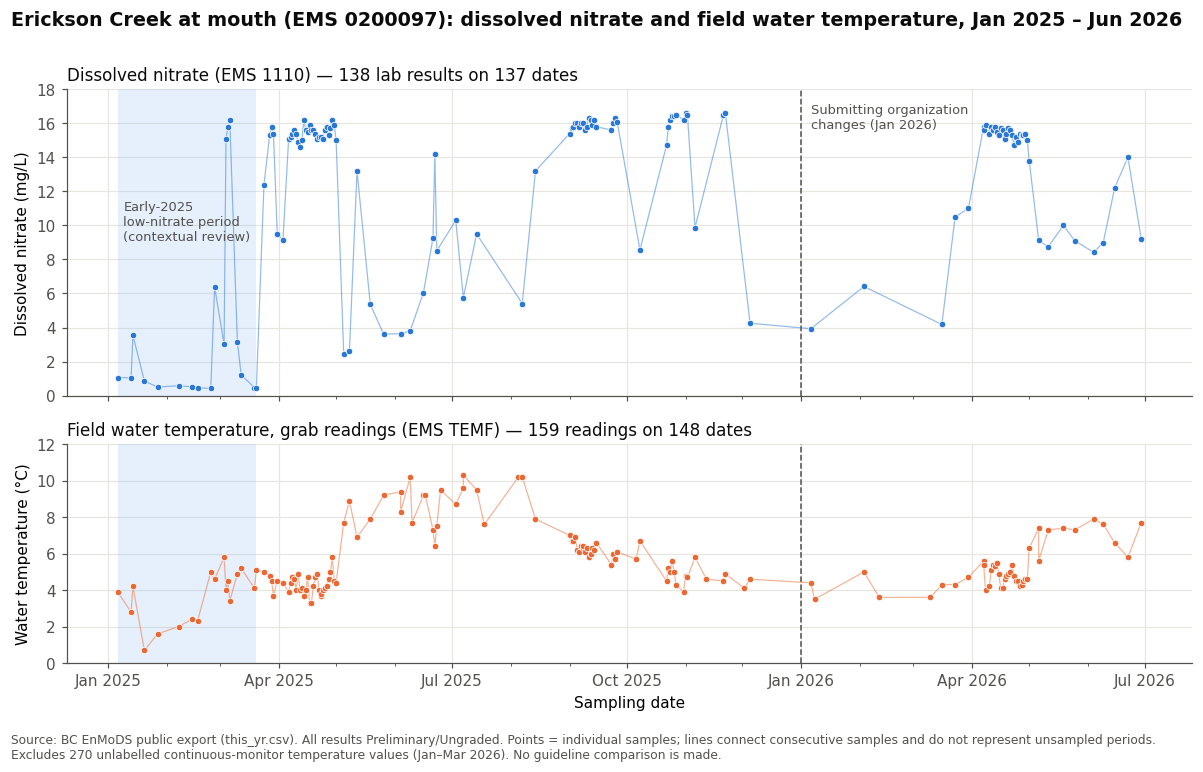

In [19]:
nit = analysis[analysis["parameter"].eq("nitrate")].sort_values("sample_date")
tmp = analysis[analysis["parameter"].eq("temperature")].sort_values("sample_date")
# Plain datetime objects keep Matplotlib date handling simple
low_start, low_end = pd.Timestamp("2025-01-06").to_pydatetime(), pd.Timestamp("2025-03-20").to_pydatetime()  # first sample -> last result <= 1.3 mg/L
change_date = pd.Timestamp("2026-01-01").to_pydatetime()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[1.4, 1])
for ax in (ax1, ax2):
    ax.axvspan(low_start, low_end, color="#9ec5f4", alpha=0.25, lw=0)
    ax.axvline(change_date, color=MUTED, ls="--", lw=1)

ax1.plot(nit["sample_date"], nit["result_numeric"], color=NITRATE_COLOR, lw=0.8, alpha=0.5)
ax1.scatter(nit["sample_date"], nit["result_numeric"], color=NITRATE_COLOR, s=18, zorder=3,
            edgecolor="white", linewidth=0.5)
ax1.set_ylabel("Dissolved nitrate (mg/L)")
ax1.set_ylim(0, 18)
ax1.set_title(f"Dissolved nitrate (EMS 1110) — {len(nit)} lab results on {nit['sample_date'].nunique()} dates",
              loc="left", color=INK)
ax1.text(mdates.date2num(low_start) + 3, 11.5, "Early-2025\nlow-nitrate period\n(contextual review)",
         fontsize=8.5, color=MUTED, va="top")
ax1.text(mdates.date2num(change_date) + 5, 17.2, "Submitting organization\nchanges (Jan 2026)",
         fontsize=8.5, color=MUTED, va="top")

ax2.plot(tmp["sample_date"], tmp["result_numeric"], color=TEMP_COLOR, lw=0.8, alpha=0.5)
ax2.scatter(tmp["sample_date"], tmp["result_numeric"], color=TEMP_COLOR, s=18, zorder=3,
            edgecolor="white", linewidth=0.5)
ax2.set_ylabel("Water temperature (°C)")
ax2.set_ylim(0, 12)
ax2.set_title(f"Field water temperature, grab readings (EMS TEMF) — {len(tmp)} readings on "
              f"{tmp['sample_date'].nunique()} dates", loc="left", color=INK)
ax2.set_xlabel("Sampling date")
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax2.xaxis.set_minor_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

fig.suptitle("Erickson Creek at mouth (EMS 0200097): dissolved nitrate and field water temperature, "
             "Jan 2025 – Jun 2026", x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
fig.text(0.01, 0.005, "Source: BC EnMoDS public export (this_yr.csv). All results Preliminary/Ungraded. "
         "Points = individual samples; lines connect consecutive samples and do not represent unsampled periods.\n"
         "Excludes 270 unlabelled continuous-monitor temperature values (Jan–Mar 2026). "
         "No guideline comparison is made.", fontsize=8, color=MUTED, va="bottom")
fig.tight_layout(rect=(0, 0.05, 1, 0.975))
fig.savefig(FIG_DIR / "time_series.png", bbox_inches="tight", facecolor="white")
plt.show()

The nitrate record shows long periods near 14–16.6 mg/L (April 2025, September–November 2025, April 2026) separated by periods of lower and more variable results: January–March 2025, May–August 2025, and December 2025–March 2026 (the latter sampled only sparsely). Grab water temperature follows a seasonal cycle, from about 0.7–3 °C in winter to about 10 °C in late summer.

## 12. Monthly / Seasonal Analysis
**Figure 2** shows monthly medians for each calendar month sampled (January 2025 – June 2026), with the number of samples above each bar. Medians are used instead of means because nitrate is strongly skewed and some months have very few samples. Each month is shown separately rather than combining the same month across years, because the record covers only about 1.5 annual cycles. Months with a single sample are hatched.

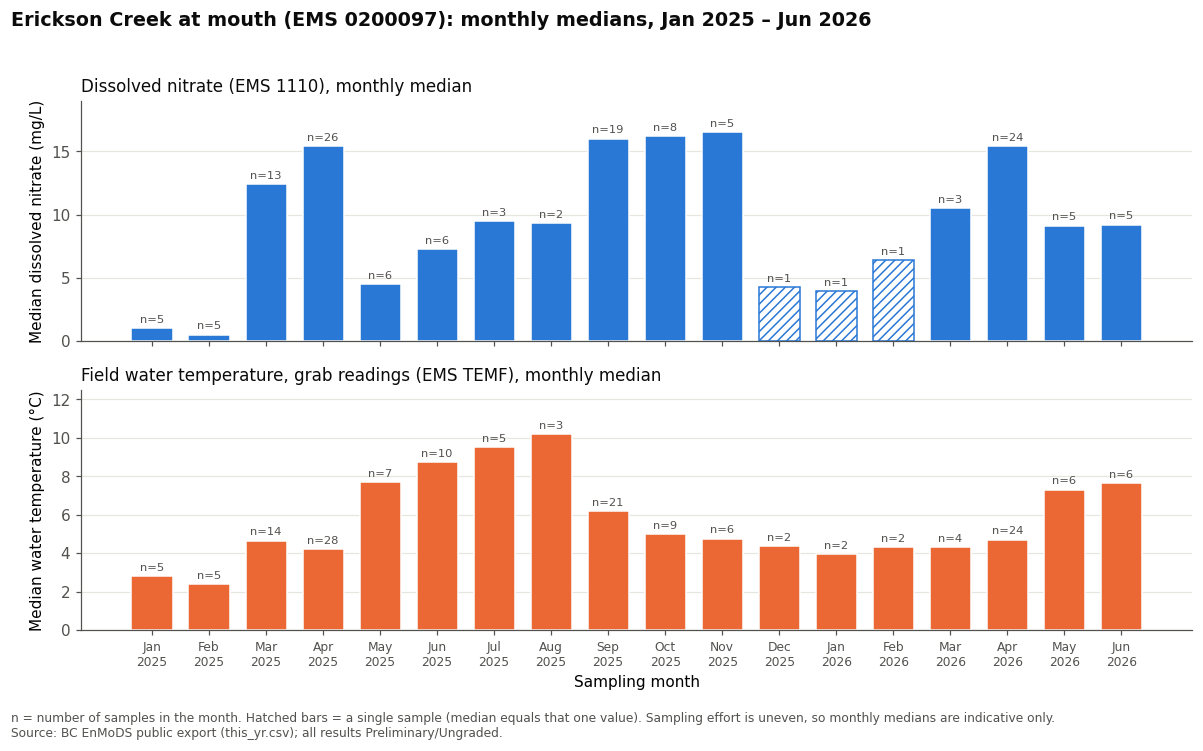

In [20]:
m = monthly.reset_index()
labels = m["month"].dt.strftime("%b\n%Y")
x = np.arange(len(m))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True)
panels = [(ax1, "nitrate_median_mg_L", "nitrate_count", NITRATE_COLOR, "Median dissolved nitrate (mg/L)", 19),
          (ax2, "temperature_median_degC", "temperature_count", TEMP_COLOR, "Median water temperature (°C)", 12.5)]
for ax, col, ncol, color, ylabel, ymax in panels:
    single = m[ncol].eq(1)
    bars = ax.bar(x, m[col], width=0.72, color=color, edgecolor="white", linewidth=1)
    for bar, is_single in zip(bars, single):
        if is_single:
            bar.set_facecolor("white"); bar.set_edgecolor(color); bar.set_hatch("////")
    for xi, val, n in zip(x, m[col], m[ncol]):
        ax.text(xi, val + ymax * 0.015, f"n={n}", ha="center", va="bottom", fontsize=7.5, color=MUTED)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, ymax)
    ax.grid(axis="x", visible=False)

ax1.set_title("Dissolved nitrate (EMS 1110), monthly median", loc="left", color=INK)
ax2.set_title("Field water temperature, grab readings (EMS TEMF), monthly median", loc="left", color=INK)
ax2.set_xticks(x, labels, fontsize=8)
ax2.set_xlabel("Sampling month")
fig.suptitle("Erickson Creek at mouth (EMS 0200097): monthly medians, Jan 2025 – Jun 2026",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
fig.text(0.01, 0.005, "n = number of samples in the month. Hatched bars = a single sample (median equals that one value). "
         "Sampling effort is uneven, so monthly medians are indicative only.\n"
         "Source: BC EnMoDS public export (this_yr.csv); all results Preliminary/Ungraded.",
         fontsize=8, color=MUTED, va="bottom")
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
fig.savefig(FIG_DIR / "monthly_pattern.png", bbox_inches="tight", facecolor="white")
plt.show()

Monthly median nitrate was highest in April 2025, September–November 2025 and April 2026 (15.4–16.5 mg/L), and lowest in January–February 2025 (1.04 and 0.52 mg/L). The single samples from December 2025 to February 2026 (3.93–6.41 mg/L) were also low but cannot be generalised to whole months. Median temperature peaked in July–August 2025 (9.5–10.2 °C). The low-nitrate months do not line up neatly with the temperature cycle, which is consistent with the weak paired correlation in Section 10.

## 13. Flagged Records Review
**Figure 3** summarises the QA/QC outcome. The left panel shows the nitrate distribution against the 1.5×IQR screening fences, with each sample coloured by its QA/QC flag. The right panel shows how every extracted record was classified.

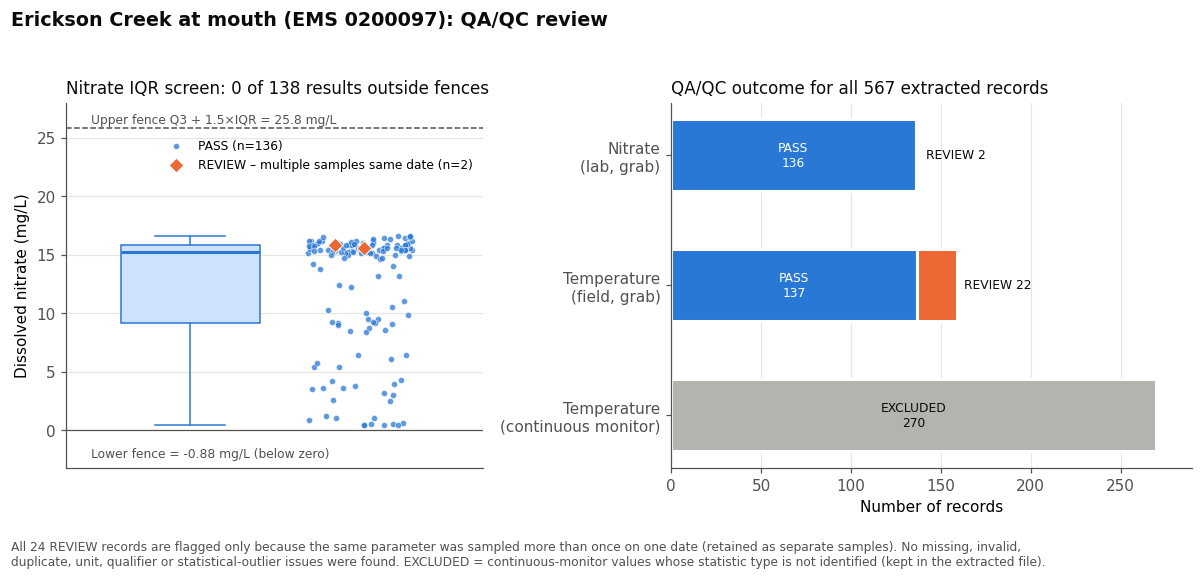

In [21]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 5.2), width_ratios=[1, 1.25])

# Left: nitrate distribution vs IQR fences
vals = nit["result_numeric"]
axL.boxplot(vals, positions=[0], widths=0.45, whis=1.5, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor="#cde2fb", edgecolor=NITRATE_COLOR),
            medianprops=dict(color=NITRATE_COLOR, lw=2), whiskerprops=dict(color=NITRATE_COLOR),
            capprops=dict(color=NITRATE_COLOR))
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.17, 0.17, len(nit))
is_review = nit["qaqc_flag"].eq("REVIEW")
axL.scatter(0.55 + jitter[~is_review], vals[~is_review], s=16, color=PASS_COLOR, alpha=0.75,
            edgecolor="white", linewidth=0.4, label=f"PASS (n={int((~is_review).sum())})")
axL.scatter(0.55 + jitter[is_review], vals[is_review], s=46, marker="D", color=REVIEW_COLOR,
            edgecolor="white", linewidth=0.6, zorder=4,
            label=f"REVIEW – multiple samples same date (n={int(is_review.sum())})")
axL.axhline(upper_fence, color=MUTED, ls="--", lw=1)
axL.axhline(0, color=MUTED, lw=0.8)
axL.text(-0.32, upper_fence + 0.4, f"Upper fence Q3 + 1.5×IQR = {upper_fence:.1f} mg/L", fontsize=8, color=MUTED)
axL.text(-0.32, -2.3, f"Lower fence = {lower_fence:.2f} mg/L (below zero)", fontsize=8, color=MUTED)
axL.set_xlim(-0.4, 0.95)
axL.set_ylim(-3.2, 28)
axL.set_xticks([])
axL.grid(axis="x", visible=False)
axL.set_ylabel("Dissolved nitrate (mg/L)")
axL.set_title(f"Nitrate IQR screen: 0 of {len(nit)} results outside fences", loc="left", color=INK)
axL.legend(loc="upper right", fontsize=8, bbox_to_anchor=(1.0, 0.93))

# Right: record classification counts
groups = [("Nitrate\n(lab, grab)", "nitrate", "Grab"),
          ("Temperature\n(field, grab)", "temperature", "Grab"),
          ("Temperature\n(continuous monitor)", "temperature", "Time Composite: Continuous Monitor")]
outcomes = [("PASS", PASS_COLOR), ("REVIEW", REVIEW_COLOR), ("EXCLUDED", EXCLUDED_COLOR)]
y = np.arange(len(groups))[::-1]
for yi, (label, p, method) in zip(y, groups):
    g = qc[qc["parameter"].eq(p) & qc["Collection_Method"].eq(method)]
    left = 0
    for outcome, color in outcomes:
        n = int(g["qaqc_flag"].eq(outcome).sum())
        if n:
            axR.barh(yi, n, left=left, color=color, edgecolor="white", linewidth=2, height=0.55)
            if n >= 40:   # label inside the segment
                axR.text(left + n / 2, yi, f"{outcome}\n{n}", ha="center", va="center", fontsize=8,
                         color="white" if outcome != "EXCLUDED" else INK)
            else:         # small segment: label just to the right of the bar
                axR.text(left + n + 4, yi, f"{outcome} {n}", ha="left", va="center", fontsize=8, color=INK)
            left += n
axR.set_yticks(y, [g[0] for g in groups])
axR.set_xlabel("Number of records")
axR.set_xlim(0, 290)
axR.grid(axis="y", visible=False)
axR.set_title(f"QA/QC outcome for all {len(qc)} extracted records", loc="left", color=INK)

fig.suptitle("Erickson Creek at mouth (EMS 0200097): QA/QC review", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold", color=INK)
fig.text(0.01, 0.005, "All 24 REVIEW records are flagged only because the same parameter was sampled more than once on one date "
         "(retained as separate samples). No missing, invalid,\nduplicate, unit, qualifier or statistical-outlier issues were found. "
         "EXCLUDED = continuous-monitor values whose statistic type is not identified (kept in the extracted file).",
         fontsize=8, color=MUTED, va="bottom")
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
fig.savefig(FIG_DIR / "qaqc_review.png", bbox_inches="tight", facecolor="white")
plt.show()

In [22]:
review_view = qc.loc[qc["qaqc_flag"].eq("REVIEW"),
                     ["source_row_number", "parameter", "Observed_Date_Time", "Result_Value", "Result_Unit",
                      "Lab_Sample_ID", "qaqc_reason"]].sort_values(["parameter", "Observed_Date_Time"])
review_view.groupby("parameter").head(6)

,source_row_number,parameter,Observed_Date_Time,Result_Value,Result_Unit,Lab_Sample_ID,qaqc_reason
104,335221,nitrate,2026-04-07T08:30-06:00,15.8,mg/L,CG2604139-002,Multiple samples on same date
105,1976724,nitrate,2026-04-07T09:53-06:00,15.6,mg/L,CG2604060-001,Multiple samples on same date
157,616740,temperature,2025-03-27T08:40-08:00,4.8,degC,NaN,Multiple samples on same date
158,484154,temperature,2025-03-27T11:00-08:00,4.8,degC,NaN,Multiple samples on same date
180,1773695,temperature,2025-04-23T08:25-08:00,3.7,degC,NaN,Multiple samples on same date
181,2610311,temperature,2025-04-23T10:30-08:00,3.8,degC,NaN,Multiple samples on same date
188,2160322,temperature,2025-04-30T08:20-08:00,4.5,degC,NaN,Multiple samples on same date
189,666570,temperature,2025-04-30T08:30-08:00,4.5,degC,NaN,Multiple samples on same date


The REVIEW records are pairs of samples or readings from the same date at different times. Seven of the 11 temperature pairs agree to within 0.2 °C; the larger differences (1.8 °C on 6 May 2026, 1.1 °C on 4 June 2025 and 0.7 °C on 7 July 2025) are between readings taken 2–5 hours apart. The full list is in `outputs/flagged_records_for_review.csv`.

## 14. Interpretation

The monitoring record for Erickson Creek at mouth contains 138 dissolved-nitrate results on 137 dates between January 2025 and June 2026. The record passed all completeness, unit, naming, qualifier and duplicate checks: no results were missing, non-numeric, non-detect or duplicated. Only 2 nitrate records (1.4 %) were flagged for review, both because two separate samples were taken on the same date. Nitrate ranged from 0.426 to 16.6 mg/L (median 15.25 mg/L, mean 12.17 mg/L). The gap between the mean and median reflects a distribution concentrated at 14–16.6 mg/L with long periods of lower values. The selected observations suggest a recurring pattern of high results in April and September–November and lower, more variable results in January–March and May–August, but with only about 1.5 years of unevenly spread samples this cannot be confirmed as a seasonal cycle. No result was statistically unusual under the 1.5×IQR screen. The lowest values (0.43–0.47 mg/L) occurred within a broader low-nitrate period in early 2025 and were retained unchanged for contextual review. Grab water temperature showed the expected seasonal cycle (monthly medians 2.4–10.2 °C), and its exact-timestamp correlation with nitrate was negligible (Pearson r = −0.12, Spearman ρ = −0.07). The available data therefore do not indicate what drives the nitrate pattern.

## 15. Limitations

- **Public secondary data.** Results come from a public EnMoDS export. Field sheets, chain-of-custody records and lab QC reports (blanks, duplicates, spikes) for these samples were not available.
- **Preliminary, ungraded results.** Every result is `Preliminary` with `Result_Grade = Ungraded`; values may still be revised or qualified in EnMoDS.
- **Limited site and process context.** Only the location name and type are known. Nothing about flow, weather, upstream activities or operations is used, so the cause of the early-2025 low-nitrate period or any other change cannot be determined.
- **Short, uneven record.** About 18 months of data, with heavy sampling in some months and single samples in others. Monthly medians are indicative only, and seasonality cannot be confirmed.
- **Statistical screening is not error detection.** The IQR screen identifies unusual values; it does not show that a value is wrong. A wide, skewed distribution also makes the IQR fences permissive.
- **Change in submitting organization (January 2026).** Detection limit, metadata conventions and timestamp offsets changed. The method and lab did not, but results either side of the change may not be fully comparable without further confirmation.
- **Nitrate reporting basis.** The export does not state whether nitrate is expressed as NO3 or NO3-N, so the results are not compared with any guideline.
- **Excluded data.** 270 continuous-monitor temperature values were excluded because the statistic each represents is not identified.
- **One site, two parameters.** Findings apply only to this location and period.
- **Not a compliance assessment.** This exploratory analysis makes no regulatory, exceedance or contamination findings.

## 16. Outputs Generated

| File | Contents |
|---|---|
| `outputs/cleaned_monitoring_data.csv` | All 297 analysis records (PASS + REVIEW) with traceability fields, original result text, numeric result, `qaqc_flag`, `qaqc_reason`, paired temperature |
| `outputs/flagged_records_for_review.csv` | The 24 REVIEW records |
| `outputs/site_parameter_summary.csv` | One row of monitoring statistics per parameter |
| `figures/time_series.png`, `figures/monthly_pattern.png`, `figures/qaqc_review.png` | Figures 1–3 |

`source_row_number` links every output record back to its row in `data/raw/this_yr.csv`.

In [23]:
OUTPUT_COLUMNS = [
    "source_row_number", "Location_ID", "Location_Name", "Location_Type",
    "parameter", "Observed_Property_Name", "Observed_Property_ID", "sample_date", "Observed_Date_Time",
    "Result_Value", "result_numeric", "Result_Unit", "Medium", "Collection_Method", "Data_Classification",
    "Fraction", "Detection_Condition", "Method_Detection_Limit", "Method_Reporting_Limit",
    "QC_Type", "Result_Status", "Result_Grade", "Analysis_Method", "Analysis_Method_ID",
    "Analyzing_Agency", "Sampling_Agency", "Activity_Name", "Lab_Sample_ID", "Lab_Batch_ID",
    "Work_Order_number", "Lab_Comment", "Field_Comment",
    "qaqc_flag", "qaqc_reason", "paired_temp_degC", "paired_with_nitrate",
]

cleaned = (qc[qc["in_analysis_subset"]]
           .sort_values(["parameter", "Observed_Date_Time"])[OUTPUT_COLUMNS]
           .assign(sample_date=lambda d: d["sample_date"].dt.strftime("%Y-%m-%d"))
           .rename(columns={"Observed_Property_Name": "parameter_code",
                            "Observed_Property_ID": "parameter_name",
                            "Result_Value": "result_value_original"}))
cleaned.to_csv(OUT_DIR / "cleaned_monitoring_data.csv", index=False)

flagged = cleaned[cleaned["qaqc_flag"].eq("REVIEW")]
flagged.to_csv(OUT_DIR / "flagged_records_for_review.csv", index=False)

summary = stats.reset_index()
first = cleaned.groupby("parameter").first()
summary.insert(0, "Location_ID", summary["parameter"].map(first["Location_ID"]))
summary.insert(1, "Location_Name", summary["parameter"].map(first["Location_Name"]))
summary.insert(3, "parameter_code", summary["parameter"].map(first["parameter_code"]))
summary.insert(4, "parameter_name", summary["parameter"].map(first["parameter_name"]))
numeric_cols = ["min", "q1", "median", "mean", "q3", "max", "std"]
summary[numeric_cols] = summary[numeric_cols].astype(float).round(3)
summary.to_csv(OUT_DIR / "site_parameter_summary.csv", index=False)

for f in ["outputs/cleaned_monitoring_data.csv", "outputs/flagged_records_for_review.csv",
          "outputs/site_parameter_summary.csv", "figures/time_series.png",
          "figures/monthly_pattern.png", "figures/qaqc_review.png"]:
    print(f"{f:45s} {Path(f).stat().st_size / 1024:7.1f} KB")

outputs/cleaned_monitoring_data.csv             102.0 KB
outputs/flagged_records_for_review.csv            8.4 KB
outputs/site_parameter_summary.csv                0.6 KB
figures/time_series.png                         336.6 KB
figures/monthly_pattern.png                     181.9 KB
figures/qaqc_review.png                         208.7 KB
